In [1]:
# importing the digits dataset
from sklearn import datasets
digits = datasets.load_digits()

# printing the digits dataset
print(digits)

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 10.,  0.,  0.],
       [ 0.,  0.,  0., ..., 16.,  9.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0.,  2., ..., 12.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]]), 'target': array([0, 1, 2, ..., 8, 9, 8]), 'frame': None, 'feature_names': ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4', 'pixel_0_5', 'pixel_0_6', 'pixel_0_7', 'pixel_1_0', 'pixel_1_1', 'pixel_1_2', 'pixel_1_3', 'pixel_1_4', 'pixel_1_5', 'pixel_1_6', 'pixel_1_7', 'pixel_2_0', 'pixel_2_1', 'pixel_2_2', 'pixel_2_3', 'pixel_2_4', 'pixel_2_5', 'pixel_2_6', 'pixel_2_7', 'pixel_3_0', 'pixel_3_1', 'pixel_3_2', 'pixel_3_3', 'pixel_3_4', 'pixel_3_5', 'pixel_3_6', 'pixel_3_7', 'pixel_4_0', 'pixel_4_1', 'pixel_4_2', 'pixel_4_3', 'pixel_4_4', 'pixel_4_5', 'pixel_4_6', 'pixel_4_7', 'pixel_5_0', 'pixel_5_1', 'pixel_5_2', 'pixel_5_3', 'pixel_5_4', 'pixel_5_5', 'pixel_5_6', 'pixel_5_7', 'pixel_6_0', '

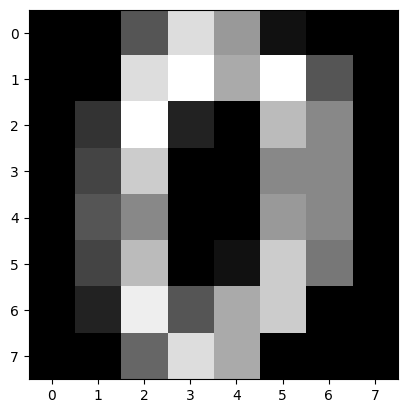

In [24]:
import matplotlib.pyplot as plt

plt.imshow(digits['data'][0].reshape((8, 8)), cmap='gray')
plt.show()

In [6]:
# splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

In [4]:
# importing the libraries

%pip install xgboost
import xgboost as xgb
import pandas as pd



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.0.1
[notice] To update, run: C:\Users\owola\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [7]:
train_model = xgb.DMatrix(X_train, label=y_train)

In [ ]:
# getting the best parameters through xgboost.cv
params = {
    'max_depth': 2,
    'eta': 1,
    'objective': 'multi:softmax',
    'num_class': 10
}

cv_results = xgb.cv(
    dtrain=train_model,
    params=params, 
    nfold=3, 
    num_boost_round=50, 
    early_stopping_rounds=10, 
    metrics="merror", 
    as_pandas=True, 
    seed = 42
    )

In [9]:
print('cv results:', cv_results)

cv results:     train-merror-mean  train-merror-std  test-merror-mean  test-merror-std
0            0.209725          0.004100          0.262064         0.025219
1            0.118040          0.006365          0.176689         0.016897
2            0.073125          0.007349          0.151448         0.012729
3            0.040089          0.003150          0.124722         0.010125
4            0.024870          0.000525          0.106162         0.007571
5            0.015961          0.003675          0.097996         0.004811
6            0.006682          0.003278          0.088344         0.005249
7            0.003712          0.002100          0.080921         0.009153
8            0.001114          0.000909          0.077209         0.008399
9            0.000371          0.000525          0.069042         0.003637
10           0.000000          0.000000          0.066815         0.004811
11           0.000000          0.000000          0.063103         0.004576
12           

In [10]:
print('accuracy:', 1-cv_results['test-merror-mean'].min())

accuracy: 0.9465478841870825


In [11]:
print('best rmse:', cv_results['test-merror-mean'].min())

best rmse: 0.05345211581291759


In [16]:
# finding the best hyperparameters through xgb.cv

# defining the hyperparameters grid
gridsearch_params = [
    (max_depth, eta, num_class)
    for max_depth in range(1, 6)
    for eta in [0.1, 0.3, 0.5, 0.7, 1]
    for num_class in range(1, 21)
]

# defining the initial best parameters

min_rmse = float("Inf")
best_params = None

for max_depth, eta, num_class in gridsearch_params:
    print("CV with max_depth={}, eta={}, num_class={}".format(max_depth, eta, num_class))
    # updating the parameters
    params['max_depth'] = max_depth
    params['eta'] = eta
    # running cv
    cv_results = xgb.cv(
        dtrain=train_model,
        params=params, 
        nfold=3, 
        num_boost_round=50, 
        early_stopping_rounds=10, 
        metrics="merror", 
        as_pandas=True, 
        seed = 42
    )
    # saving the best parameters
    mean_rmse = cv_results['test-merror-mean'].min()
    boost_rounds = cv_results['test-merror-mean'].argmin()
    print("\tRMSE {} for {} rounds".format(mean_rmse, boost_rounds))
    if mean_rmse < min_rmse:
        min_rmse = mean_rmse
        best_params = (max_depth, eta, num_class)


CV with max_depth=1, eta=0.1, num_class=1
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=2
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=3
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=4
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=5
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=6
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=7
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=8
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=9
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=10
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=11
	RMSE 0.12397921306607275 for 49 rounds
CV with max_depth=1, eta=0.1, num_class=12
	RMSE 0.12397921306607275 for 49 rounds
CV with max_d

In [17]:
print("Best params: max_depth = {}, eta = {}, RMSE: {}".format(best_params[0], best_params[1], min_rmse))

Best params: max_depth = 2, eta = 0.5, RMSE: 0.03934669636228657


In [18]:
#getting the accuracy of the model
params['max_depth'] = best_params[0]
params['eta'] = best_params[1]

model = xgb.train(
    params,
    train_model,
    num_boost_round=50
)

test_model = xgb.DMatrix(X_test)
y_pred = model.predict(test_model)

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print('accuracy:', accuracy)

accuracy: 0.9644444444444444
